# Gesetzliche Grenzwerte (Teil 1)

Zeitreihenanalyse der Luftqualität

## 1 Luftqualität

**Feinstaub, Stickstoffoxide, Benzol, Schwefeldioxid, Ozon** - das sind
Schadstoffe in der Luft, denen wir täglich ausgesetzt sind und die
**gesundheitsschädlich** sind.

Wegen der Gesundheitsgefahr gelten für diese Schadstoffe gesetzliche
Grenzwerte. Aber werden diese Grenzwerte in der Realität auch
eingehalten?

Um die Einhaltung der Grenzwerte zu kontrollieren, gibt es an vielen
Orten in Deutschland Messstationen, die die Schadstoffkonzentration in
der Luft messen.

In diesem interaktiven Arbeitsblatt werden die Daten der Messstation
Bielefeld-Ost (BIEL) analysiert. Dabei wird untersucht, **ob die
gesetzlich vorgeschriebenen Grenzwerte tatsächlich eingehalten wurden**.

Quelle: [Deutsche
Umwelthilfe](https://www.duh.de/themen/luftqualitaet/schadstoffe/feinstaub/)

<figure>
<img src="figures/schornsteine.png"
alt="Foto „Industrielle Schornsteine - Luftverschmutzung“ von Tim Reckmann unter der Lizenz CC BY 2.0 via Flickr." />
<figcaption aria-hidden="true">Foto „Industrielle Schornsteine -
Luftverschmutzung“ von <a
href="https://www.flickr.com/photos/115225894@N07">Tim Reckmann</a>
unter der Lizenz <a
href="https://creativecommons.org/licenses/by/2.0/?ref=openverse">CC BY
2.0</a> via <a
href="https://www.flickr.com/photos/115225894@N07/54277887083">Flickr</a>.</figcaption>
</figure>

## 2 Messstation - Bielefeld-Ost (BIEL)

Der Messcontainer steht auf einer Grünfläche am Rande des Ravensberger
Parks, in der Nähe der Kreuzung Hermann-Delius-Straße / Bleichstraße.
Das Umfeld ist locker bebaut mit vielen Grünflächen. Das Stadtzentrum
Bielefeld liegt etwa 1,2 km westlich. Die autobahnähnlich ausgebaute B
61 verläuft ca. 1,5 km westlich in Nord-Süd-Richtung.

[Quelle: LANUK](https://luftqualitaet.nrw.de/steckbrief.php)

<figure>
<img src="figures/messstation.png" alt="Foto der Station" />
<figcaption aria-hidden="true">Foto der Station</figcaption>
</figure>

In der Karte ist die genaue Position der Messstation markiert.
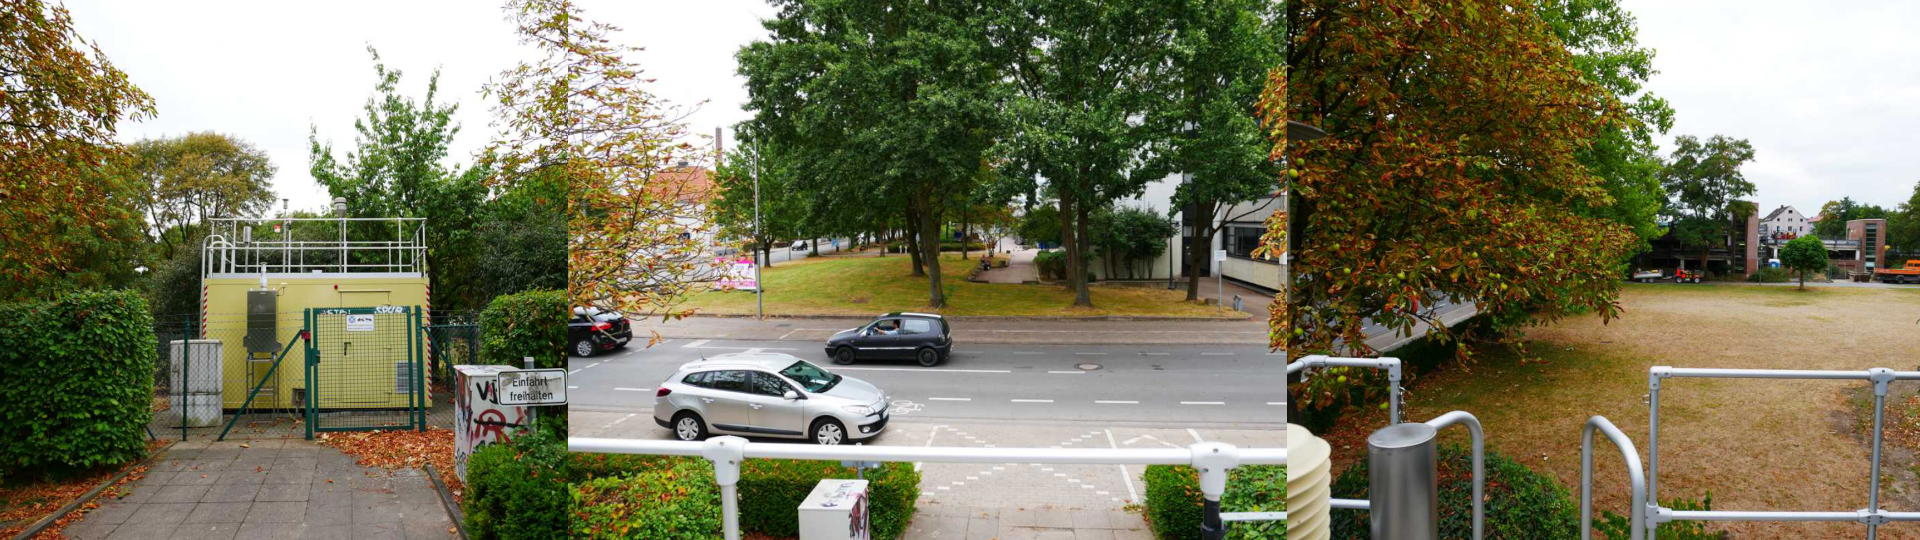
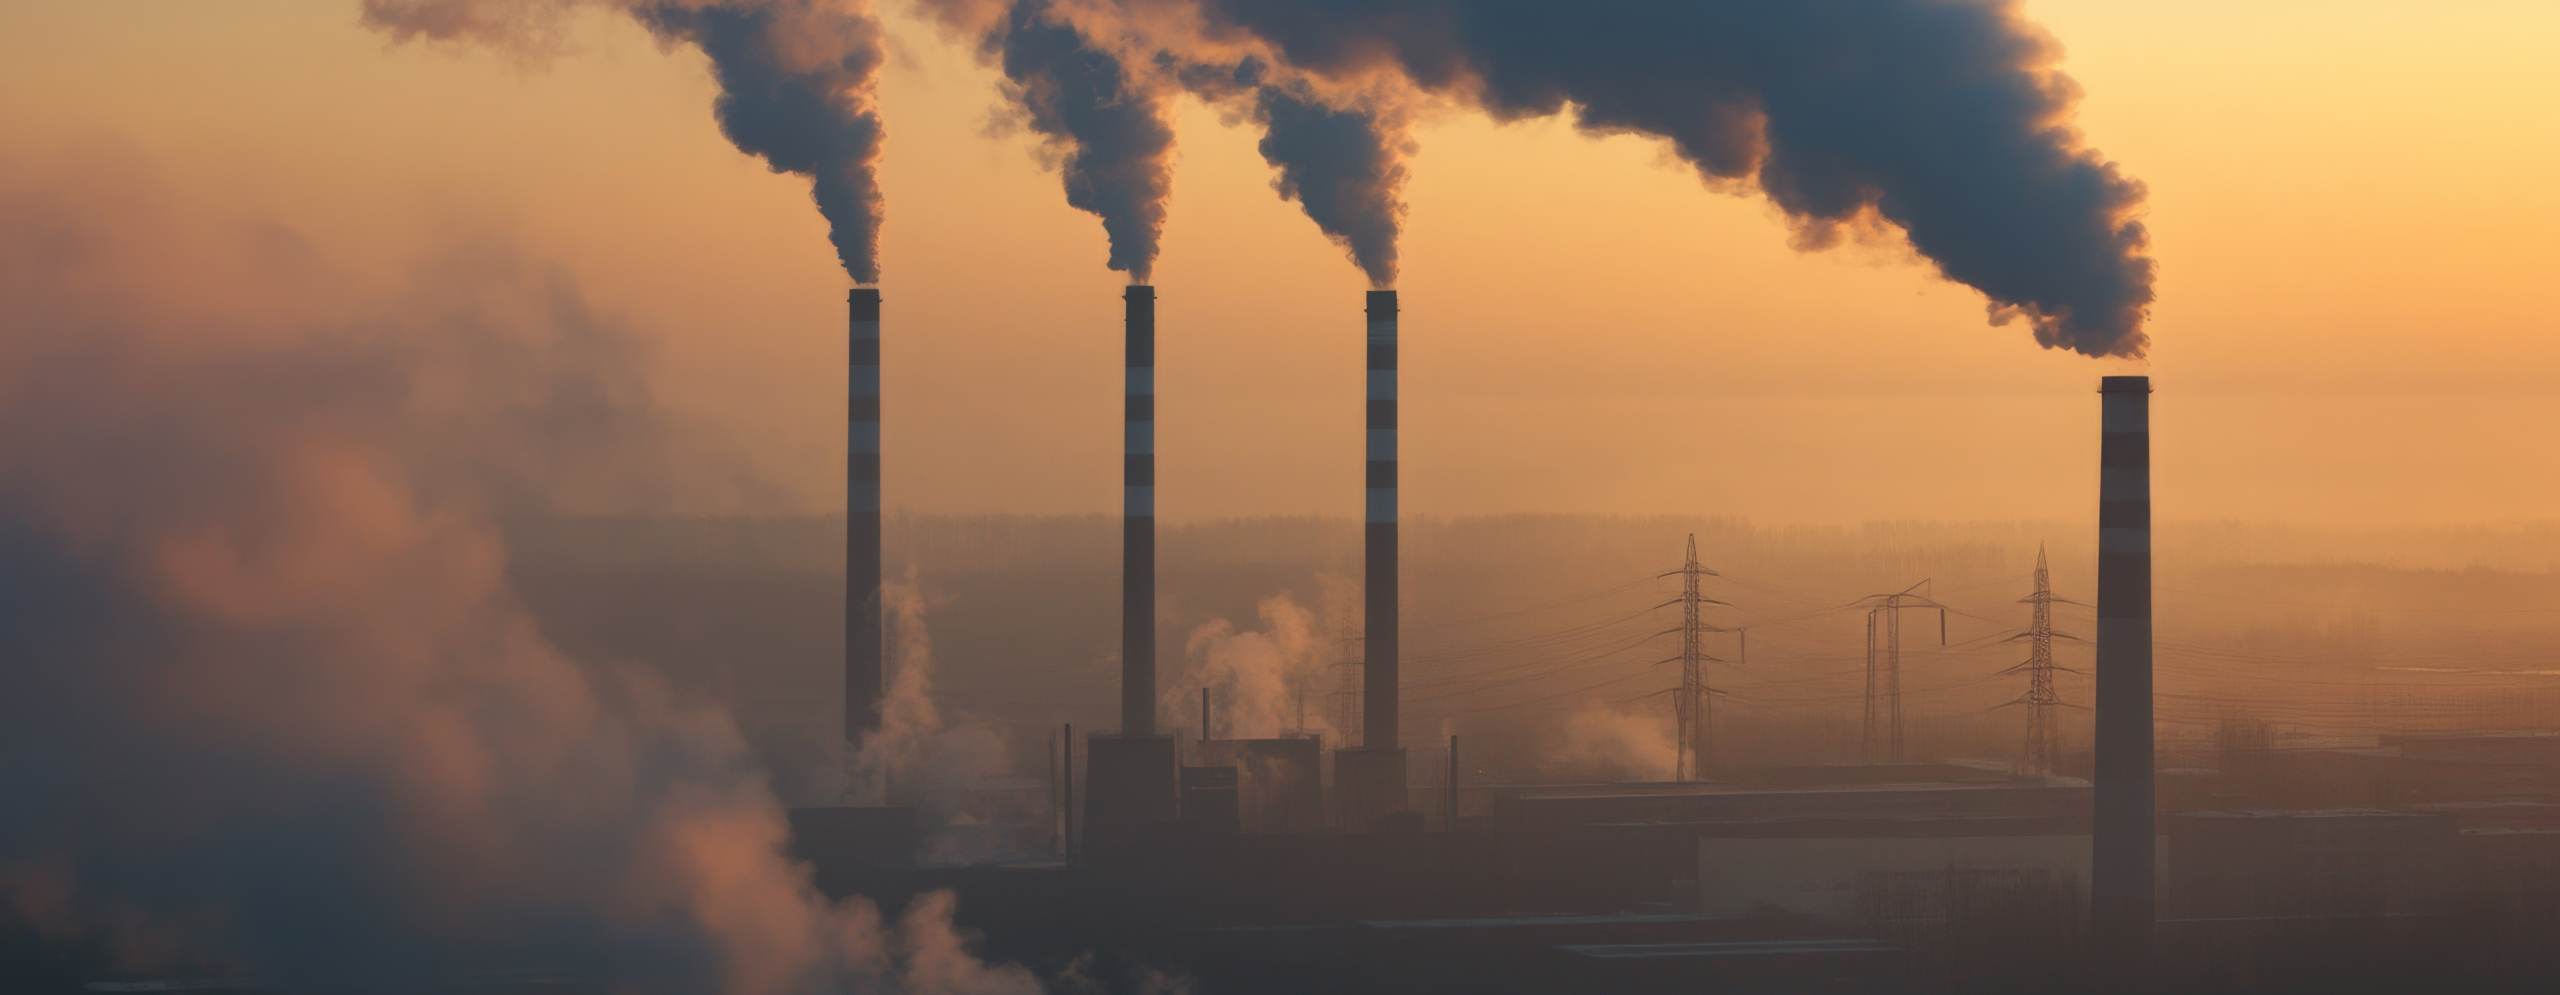

In [ ]:
# Code zum Erzeugen der Karte
from folium import Map, Marker

# Breiten- und Längengrad des Containers
location = 52.023155, 8.548362

# Karte erzeugen
map = Map(location, zoom_start=14)

# Marker hinzufügen
marker = Marker(location=location)
# Marker zur Karte hinzufügen
marker.add_to(map)

# Karte anzeigen
map

## 3 Daten einlesen

Die Daten der Messstation sind bereits heruntergeladen und werden nun
mit dem Befehl `read_csv()` eingelesen.

Dabei werden die Daten in ein sogenanntes
[:DataFrame](../../../nutshell.qmd#DataFrame) mit dem Namen `df`
geschrieben. Ein DataFrame ist eine tabellarische Datenstruktur, die aus
Spalten und Zeilen besteht – ähnlich den Tabellen, wie du sie
möglicherweise aus Programmen wie Excel kennst.

Um die Daten anschließend anzuzeigen, muss der Variablennamen `df`
(engl. *DataFrame*) am Ende der Zelle eingegeben werden.

Die Daten umfassen verschiedene Schadstoffe:

|          Kürzel | Name                           | Einheit          |
|----------------:|:-------------------------------|------------------|
|              NO | Stickstoffmonoxid              | µg/m<sup>3</sup> |
|  NO<sub>2</sub> | Stickstoffdioxid               | µg/m<sup>3</sup> |
|   O<sub>3</sub> | Ozon                           | µg/m<sup>3</sup> |
| PM<sub>10</sub> | Feinstaub (Particulate Matter) | µg/m<sup>3</sup> |
|  SO<sub>2</sub> | Schwefeldioxid                 | µg/m<sup>3</sup> |

Die Messwerte liegen jeweils als **Tagesmittelwert** vor.

Die Daten sind in **µg/m<sup>3</sup>** (Mikrogramm pro Kubikmeter)
angegeben.

Die Daten umfassen den Zeitraum von **1989 bis 2022**.

Solch eine zeitliche Abfolge von Messdaten wird auch
[:Zeitreihe](../../../nutshell.qmd#Zeitreihe) genannt.

In [ ]:
# Data Science Bibliothek importieren
import pandas as pd

# Daten einlesen
df = pd.read_csv('data/air_quality.csv', index_col='time', parse_dates=True)

# Daten anzeigen
df

> **Hinweis**
>
> Der Eintrag `NaN` (Not a Number) bedeutet, dass an der betreffenden
> Stelle kein Messwert vorliegt (z.B. weil keine Messung durchgeführt
> wurde oder ein Messfehler vorliegt).

## 4 Daten explorieren

### 4.1 Liniendiagramm

Mit der Funktion `px.line(...)` der Bibliothek `plotly` können die Daten
in einem [:Liniendiagramm](../../../nutshell.qmd#Liniendiagramm)
visualisiert werden.

In [ ]:
# Bibliothek zum Erstellen von Diagrammen (plots) importieren
import plotly.express as px

# Liniendiagramm aus den Daten df erzeugen
fig = px.line(df)

# Achsenbeschriftungen einfügen
fig.update_xaxes(title='Zeitpunkt der Messung')
fig.update_yaxes(title='Schadstoffkonzentration<br>[µg/m<sup>3</sup>]')
fig.update_legends(title='Schadstoff')

# Diagramm anzeigen
fig.show()

> **Tipp**
>
> Bewege die Maus über das Diagramm, um einzelne Datenpunkte genauer zu
> betrachten. Durch Klicken auf eine Variable kann diese ein- oder
> ausgeblendet werden.

### 4.2 Boxplot

Eine weitere Möglichkeit zur Darstellung der Messwerte sind sogenannte
[:Boxplots](../../../nutshell.qmd#Boxplots). Diese eignen sich
besonders, um die Verteilung und Streuung von Messwerte darzustellen.

#### Aufgabe 1

-   Erstelle ein Boxplot, das die Verteilung der Schadstoffe zeigt.  
-   Verwende dafür die Funktion `px.box(...)`, analog zu `px.line(...)`
    aus dem Beispiel oben.  
-   Füge geeignete Achsenbeschriftungen hinzu.

*(5 Minuten)*

In [ ]:
# Boxplot erzeugen

# Achenbeschriftungen einfügen

# Diagramm anzeigen

## 5 Feinstaub

[:Feinstaub](../../../nutshell.qmd#Feinstaub) besteht aus kleinsten
Partikeln, die sich neben ihrer Größe auch durch ihre chemischen
Eigenschaften unterscheiden. Zu Feinstaub zählen alle Partikel, deren
Durchmesser kleiner als 10 Mikrometer (µm) ist. Häufig wird dafür das
Kürzel PM<sub>10</sub> (**PM** = **P**articulate **M**atter) verwendet.

### 5.1 Gesetzliche Grenzwerte für Feinstaub

Zum Schutz der menschlichen Gesundheit gelten seit dem 1. Januar 2005
**europaweit Grenzwerte für Feinstaub**:

-   Der Tagesgrenzwert beträgt 50 µg/m<sup>3</sup> und darf nicht öfter
    als 35mal im Jahr überschritten werden.
-   Der zulässige Jahresmittelwert beträgt 40 µg/m<sup>3</sup>.

Um zu überprüfen, ob die gesetzlichen Bestimmungen hinsichtlich des
Tagesgrenzwertes eingehalten wurden, muss die Anzahl der Tage bestimmt
werden, an denen der Grenzwert über 50 µg/m<sup>3</sup> lag.

> **Hinweis**
>
> Die Weltgesundheitsorganisation WHO empfiehlt einen Richtwert von 5
> µg/m<sup>3</sup> im Jahresmittel für PM<sub>2,5</sub> und 15
> µg/m<sup>3</sup> im Jahresmittel für PM<sub>10</sub> (WHO 2021).
>
> Es gibt keine Feinstaubkonzentration, unterhalb derer eine schädigende
> Wirkung ausgeschlossen werden kann

### 5.2 Daten selektieren

Zunächst wird die Spalte `PM10`, welche die Feinstaubmesswerte enthält,
ausgewählt (selektiert) und in einer Variable mit dem Namen `values`
gespeichert.

Die Variable `values` enthält somit eine Reihe (engl.
[:Series](../../../nutshell.qmd#Series)) von Messwerten der
Feinstaubkonzentration.

In [ ]:
# Spalte PM10 selektieren 
values = df['PM10']
values

> **Hinweis**
>
> Der Wert `NaN`(Not a number) bedeutet, dass für den jeweiligen
> Zeitpunkt kein Wert vorliegt.

Um nun die Anzahl der Überschreitungen pro Jahr zu ermitteln, wird wie
folgt vorgegangen:

1.  Zunächst werden alle Tage ermittelt, an denen der Tagesgrenzwert
    überschritten wurde. Dazu werden die Daten anhand der Bedingung für
    eine Grenzwertüberschreitung gefiltert.
2.  Anschließend werden die Grenzwertüberschreitungen nach Jahren
    gruppiert und die Anzahl der Überschreitungen pro Jahr gezählt.

### 5.3 Daten filtern

Anschließend werden die Daten gefiltert. Dazu wird zunächst eine
Bedingung festgelegt (`values > 50`). Die Bedingung wird dabei für jeden
Wert der Reihe einzeln geprüft.

-   Die Bedingung ist **erfüllt** (`True`), wenn der jeweilige Wert
    größer als 50 ist.
-   Die Bedingung ist **nicht erfüllt** (`False`), wenn der jeweilige
    Wert kleiner oder gleich 50 ist.

In [ ]:
# Bedingung festlegen
cond = values > 50
cond

Anschließend werden die Werte entsprechend der Bedingung gefiltert. Die
Variable `filtered` enthält nun nur noch die Messwerte, bei denen der
Tagesgrenzwert überschritten wurde.

Der Ausdruck `values[cond]` filtert die Werte so, dass nur noch jene in
der Reihe verbleiben, bei denen die Bedingung `cond` erfüllt ist
(`True`) – also eine Grenzwertüberschreitung vorliegt.

In [ ]:
# Daten enstprechend der Bedingung filtern
filtered = values[cond]
filtered

Mit der Funktion `px.scatter()` können wir ein Streudiagramm (engl.
*scatter plot*) der gefilterten Daten erzeugen. Darauf sehen wir alle
Messzeitpunkte, an denen der Tagesgrenzwert überschritten wurde.

In [ ]:
# Streudiagramm erzeugen
fig = px.scatter(filtered, title='Grenzwertüberschreitungen')

# Achsenbeschriftungen anpassen
fig.update_xaxes(title='Zeitpunkt')
fig.update_yaxes(title='Messwert')

# Streudiagramm anzeigen
fig.show()

### 5.4 Gruppieren und aggregieren

Um nun die Anzahl der Tage pro Jahr zu bestimmen, an denen der Grenzwert
überschritten wurde, müssen die Daten nach Jahren gruppiert und
anschließend die Anzahl der Einträge gezählt werden.

Mit der Methode `resample()` können die Daten in Zeitintervalle
zusammengefasst (**gruppiert**) werden. In diesem Beispiel wird die
Regel `'YS'` (*year start*) angewandt, um die Daten nach Jahren zu
gruppieren. Die Gruppe mit dem Eintrag `2002-01-01` umfasst demnach
beispielsweise die Daten aus dem Zeitraum vom 01.01.2002 bis zum
31.12.2002.

Anschließend wird mit der Methode `count()` die Anzahl der Tage pro Jahr
ermittelt, an denen der Grenzwert überschritten wurde. Dieser Schritt
wird auch als **Aggregation** bezeichnet. Das bedeutet, dass mehrere
Einträge zu einem Wert (in diesem Fall der Anzahl) zusammengefasst
werden.

Weitere **Aggregationsfunktionen** sind z.B. `mean()` für den
Mittelwert, `sum()` für die Summe der Werte, `min()` für den kleinsten
Wert (Minimum) oder `max()` für den größten Wert (Maximum).

In [ ]:
# Daten nach Jahren gruppieren
grouped = filtered.resample('YS')

# Anzahl der Einträge je Gruppe bestimmen (aggregieren)
aggregated = grouped.count()
aggregated

Die `resample` Funktion akzeptiert unter anderem die folgenden Regeln:

| Kürzel | Bedeutung               |
|-------:|:------------------------|
|      D | Tag (day)               |
|      W | Woche (week)            |
|     MS | Monat (month start)     |
|     QS | Quartal (quarter start) |
|     YS | Jahr (year start)       |

Hier nochmal alle Schritte zusammengefasst:

In [ ]:
# Feinstaub-Spalte selektieren
values = df['PM10']

# Bedingung für Überschreitung des Tagesgrenzwerts festlegen
cond = values > 50

# Daten anhand der Bedingung filtern
filtered = values[cond]

# Daten nach Jahren gruppieren
grouped = filtered.resample('YS')

# Anzahl der Einträge je Gruppe bestimmen (aggregieren)
aggregated = grouped.count()

Mit der Funktion `bar()` können die aggregierten Daten nun in einem
Säulendiagramm (engl. *bar chart*) dargestellt werden.

In [ ]:
# Daten in einem Säulendiagram anzeigen
fig = px.bar(aggregated, title='Anzahl der Tage mit Grenzwertüberschreitung (Feinstaub)')

fig.update_xaxes(title='Jahr')
fig.update_yaxes(title='Anzahl Tage')
fig.update_legends(title='Schadstoff')

fig.show()

#### Aufgabe 2

-   Betrachte das Säulendiagramm und überprüfe, ob die gesetzlichen
    Bestimmungen hinsichtlich des Tagesgrenzwertes eingehalten wurden!

*(5 Minuten)*

> **Zur Erinnerung**
>
> Der Tagesgrenzwert beträgt 50 µg/m<sup>3</sup> und darf nicht öfter
> als 35-mal im Jahr überschritten werden.

**Antwort:**

*Klicke hier, um deine Antwort einzugeben.*

### 5.5 Jahresmittelwert

#### Aufgabe 3

-   Überprüfe, ob der Grenzwert für den Jahresmittelwert (40
    µg/m<sup>3</sup>) der Feinstaubkonzentration eingehalten wurde!
-   Ermittel dafür die Jahresmittelwerte der Feinstaubkonzentration.

*(10 Minuten)*

> **Tipp**
>
> Du benötigst dafür die Funktion `resample()` und die Aggregatfunktion
> `.mean()`.

In [ ]:
# Jahresmittelwerte bestimmen

# Jahresmittelwerte ausgeben


**Antwort**

*Klicke hier, um deine Antwort einzugeben.*

## 6 Weitere Schadstoffe in der Luft

### 6.1 Stickstoffdioxid

Stickstoffdioxid (NO<sub>2</sub>) entsteht als Produkt unerwünschter
Nebenreaktionen bei Verbrennungsprozessen. Die Hauptquellen von
Stickstoffoxiden sind Verbrennungsmotoren und Feuerungsanlagen für
Kohle, Öl, Gas, Holz und Abfälle. In Ballungsgebieten ist der
Straßenverkehr die bedeutendste Quelle für Stickstoffoxide
(NO<sub>x</sub>).

In der Umwelt vorkommende Stickstoffdioxid-Konzentrationen sind vor
allem für Asthmatiker ein Problem. Zudem erhöht eine jahrzehntelange
Belastung durch NO<sub>2</sub> das Risiko an Herz-Kreislauferkrankungen
zu versterben (Quelle: Umweltbundesamt).

Stickstoffdioxid kann Pflanzen schädigen und unter anderem ein
Gelbwerden der Blätter, vorzeitiges Altern und Kümmerwuchs bewirken.
Zudem trägt Stickstoffdioxid zur Überdüngung und ⁠Versauerung⁠ von Böden
und in geringem Maße auch von Gewässern bei.

### 6.2 Schwefeldioxid

Schwefeldioxid (SO<sub>2</sub>) ist ein farbloses, stechend riechendes,
wasserlösliches Gas, das Mensch und Umwelt beeinträchtigt.

Schwefeldioxid entsteht überwiegend bei Verbrennungsvorgängen fossiler
Energieträger wie Kohle und Öl durch Oxidation des im Brennstoff
enthaltenen Schwefels.

Schwefeldioxid reizt die Schleimhäute und kann zu Augenreizungen und
Atemwegsproblemen führen.

### 6.3 Grenzwerte

Auch für Stickstoffdioxid und Schwefeldioxid existieren gesetzliche
Grenzwerte.

#### Aufgabe 4

-   Überprüfe, ob die gesetzlichen Bestimmungen hinsichtlich des Tages-
    und Jahresgrenzwerte für die Schadstoffe NO<sub>2</sub> und
    SO<sub>2</sub> eingehalten wurden!

*(15 Minuten)*

| Schadstoff | Tagesgrenzwert | Jahresgrenzwert |
|-----------------------:|:-----------------------|:-----------------------|
| NO<sub>2</sub> | \- | Der Grenzwert für den Jahresmittelwert beträgt 40 µg/m<sup>3</sup> |
| SO<sub>2</sub> | Der Tagesgrenzwert von 125 µg/m<sup>3</sup> darf nicht öfter als dreimal im Kalenderjahr überschritten werden. | Der Zum Schutz der Vegetation beträgt der kritische Wert als Jahresmittelwert 20 µg/m<sup>3</sup>. |

> **Tipp**
>
> Orientiere dich an dem Beispiel oben, um den Tagesgrenzwert zu
> überprüfen.

In [ ]:
# Hier Programmcode einfügen

**Antwort**

*Klicke hier, um deine Antwort einzugeben.*